# TMDB TV shows: exploration and popularity prediction
Sections: 1 load and clean, 2 data quality, 3 landscape, 4 genre effect (Netflix), 5 recency, 6 modelling with leakage check.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
BLUE, ORANGE, RED, GREY = "#2a78d6", "#eb6834", "#e34948", "#c3c2b7"
raw = pd.read_csv("../data/tmdb_tv_shows/TMDB_tv_dataset_v3.csv")
# keep the most-voted copy of each id
df = (raw.sort_values(["vote_count", "popularity"], ascending=False)
         .drop_duplicates("id").sort_index().reset_index(drop=True))
df["first_air_date"] = pd.to_datetime(df["first_air_date"], errors="coerce")
df["last_air_date"] = pd.to_datetime(df["last_air_date"], errors="coerce")
df["year"] = df.first_air_date.dt.year
df["log_pop"] = np.log1p(df.popularity)
print(len(raw), "->", len(df))

168639 -> 164705


## 1. Data quality
Intuition: a rating is only informative if enough people voted. Check how sparse votes are before trusting `vote_average`.

vote_count
0       107419
1-5      40776
6-99     13480
100+      3030
Name: count, dtype: int64


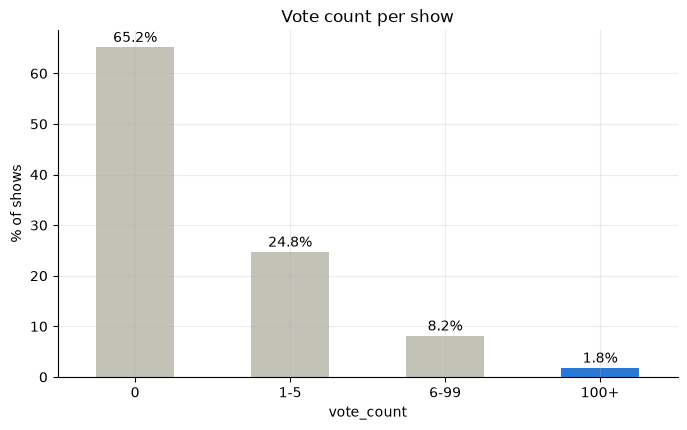

tagline                 96.8
created_by              78.2
homepage                69.4
production_companies    64.6
production_countries    53.9
backdrop_path           53.6
overview                44.3
networks                41.6
genres                  40.8
poster_path             35.5
dtype: float64


In [2]:
bins = pd.cut(df.vote_count, [-1, 0, 5, 99, 1e9], labels=["0", "1-5", "6-99", "100+"])
s = bins.value_counts(normalize=True).reindex(["0", "1-5", "6-99", "100+"]) * 100
print(bins.value_counts().reindex(["0", "1-5", "6-99", "100+"]))
ax = s.plot.bar(color=[GREY, GREY, GREY, BLUE], rot=0); ax.set_ylabel("% of shows"); ax.set_title("Vote count per show")
for i, v in enumerate(s): ax.text(i, v + 1, f"{v:.1f}%", ha="center")
plt.show()
print((df.isna().mean() * 100).round(1).sort_values(ascending=False).head(10))

## 2. Landscape

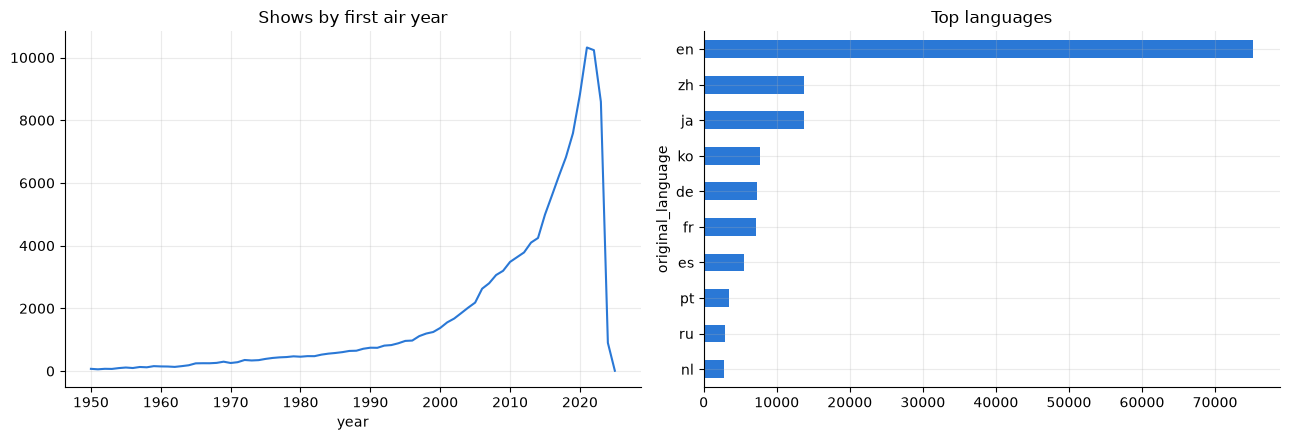

status
Ended               92438
Returning Series    64853
Canceled             4452
In Production        2161
Planned               569
Pilot                 232
Name: count, dtype: int64

type
Scripted       126396
Documentary     13415
Miniseries      10539
Reality          9473
Talk Show        2934
Video            1366
News              582
Name: count, dtype: int64


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
df[df.year.between(1950, 2025)].groupby("year").size().plot(ax=ax[0], color=BLUE); ax[0].set_title("Shows by first air year")
df.original_language.value_counts().head(10).sort_values().plot.barh(ax=ax[1], color=BLUE); ax[1].set_title("Top languages")
plt.tight_layout(); plt.show()
print(df.status.value_counts(), df.type.value_counts(), sep="\n\n")

In [4]:
g = df.assign(g=df.genres.str.split(", ")).explode("g").dropna(subset=["g"])
rated = g[g.vote_count >= 100]
t = g.groupby("g").agg(n=("id", "size"), med_pop=("popularity", "median")).join(
    rated.groupby("g").agg(n_rated=("id", "size"), avg_rating=("vote_average", "mean")))
t.sort_values("n", ascending=False).round(2)

,n,med_pop,n_rated,avg_rating
g,,,,
Drama,33193,2.52,1763.0,7.64
Comedy,22948,2.29,1048.0,7.74
Documentary,21357,0.84,106.0,7.56
Animation,11829,3.09,784.0,7.95
Reality,10759,1.36,50.0,7.10
Action & Adventure,7201,4.50,787.0,7.73
Crime,6755,2.62,447.0,7.61
Family,6360,2.14,231.0,7.72
Sci-Fi & Fantasy,6300,5.30,908.0,7.67


Popularity is heavily skewed, so everything downstream uses `log1p(popularity)`. Intuition: a few mega shows dominate the raw scale and would dominate any squared-error fit.

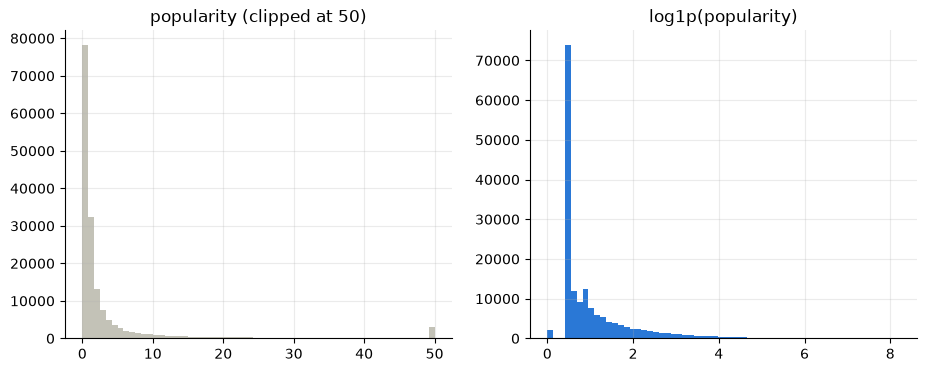

count    164705.00
mean          5.98
std          42.50
min           0.00
50%           0.87
90%           8.53
99%          84.74
max        3707.01
Name: popularity, dtype: float64


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(df.popularity.clip(upper=50), bins=60, color=GREY); ax[0].set_title("popularity (clipped at 50)")
ax[1].hist(df.log_pop, bins=60, color=BLUE); ax[1].set_title("log1p(popularity)")
plt.show()
print(df.popularity.describe(percentiles=[.5, .9, .99]).round(2))

## 3. Genre effect on Netflix shows
Netflix subset by `networks` field (workaround: the dataset is all-network, not Netflix only). OLS on log popularity with language, type and year controls, HC3 robust errors. This is an association, not causation.

netflix shows: 1929 | with genres+year: 1759
R2: 0.31


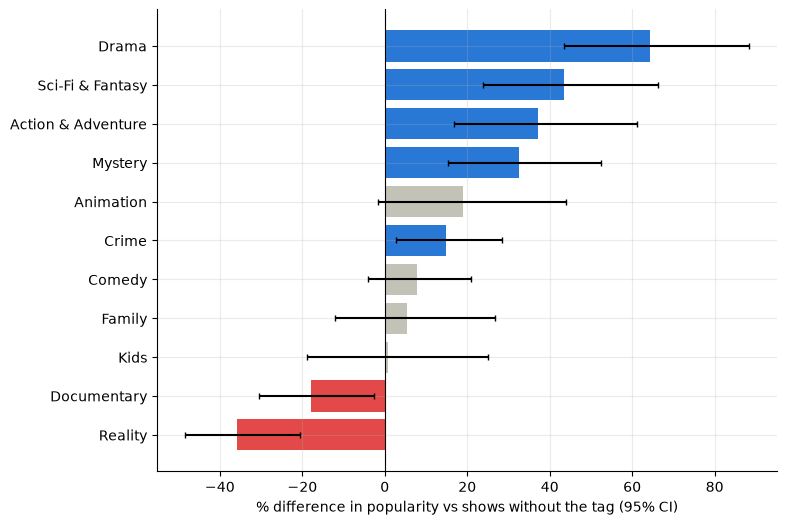

,coef,se,pct_effect,lo,hi
Drama,0.5,0.1,64.4,43.6,88.3
Sci-Fi & Fantasy,0.4,0.1,43.5,23.9,66.2
Action & Adventure,0.3,0.1,37.1,16.7,61.1
Mystery,0.3,0.1,32.5,15.2,52.3
Animation,0.2,0.1,18.9,-1.8,43.9
Crime,0.1,0.1,14.9,2.8,28.5
Comedy,0.1,0.1,7.8,-4.0,20.9
Family,0.1,0.1,5.4,-12.2,26.6
Kids,0.0,0.1,0.7,-18.9,25.1
Documentary,-0.2,0.1,-17.8,-30.5,-2.7


In [6]:
nf = df[df.networks.fillna("").str.contains("Netflix")].dropna(subset=["genres", "year"]).copy()
print("netflix shows:", df.networks.fillna("").str.contains("Netflix").sum(), "| with genres+year:", len(nf))
gen = nf.genres.str.get_dummies(sep=", ")
gen = gen.loc[:, gen.sum() >= 30]
lang = pd.get_dummies(nf.original_language.where(nf.original_language.isin(["en", "ko", "ja", "es", "fr", "de"]), "other"), prefix="lang", drop_first=True)
typ = pd.get_dummies(nf.type, prefix="type", drop_first=True)
X = pd.concat([gen, lang, typ, (nf.year - 2000).rename("year")], axis=1).astype(float)
X.insert(0, "const", 1.0)
y = nf.log_pop.values
A = X.values; beta = np.linalg.lstsq(A, y, rcond=None)[0]
res = y - A @ beta
H = np.einsum("ij,jk,ik->i", A, np.linalg.pinv(A.T @ A), A)
meat = (A * (res / (1 - H))[:, None]).T @ (A * (res / (1 - H))[:, None])
cov = np.linalg.pinv(A.T @ A) @ meat @ np.linalg.pinv(A.T @ A)
se = np.sqrt(np.diag(cov))
out = pd.DataFrame({"coef": beta, "se": se}, index=X.columns).loc[gen.columns]
out["pct_effect"] = (np.exp(out.coef) - 1) * 100
out["lo"] = (np.exp(out.coef - 1.96 * out.se) - 1) * 100
out["hi"] = (np.exp(out.coef + 1.96 * out.se) - 1) * 100
print("R2:", round(1 - res.var() / y.var(), 2))
out = out.sort_values("pct_effect")
fig, ax = plt.subplots(figsize=(8, 6))
cols = [BLUE if l > 0 else (RED if h < 0 else GREY) for l, h in zip(out.lo, out.hi)]
ax.barh(out.index, out.pct_effect, xerr=[out.pct_effect - out.lo, out.hi - out.pct_effect], color=cols, ecolor="k", capsize=2)
ax.axvline(0, color="k", lw=.8); ax.set_xlabel("% difference in popularity vs shows without the tag (95% CI)")
plt.show()
out.round(1).sort_values("pct_effect", ascending=False)

## 4. Recency
Popularity is current attention, so it decays after a show stops airing.

        median  size
bucket              
<=1      14.41   307
1-2       7.54   396
2-3       6.92   288
3-4       7.18   270
4-5       6.86   204
5+        5.86   240


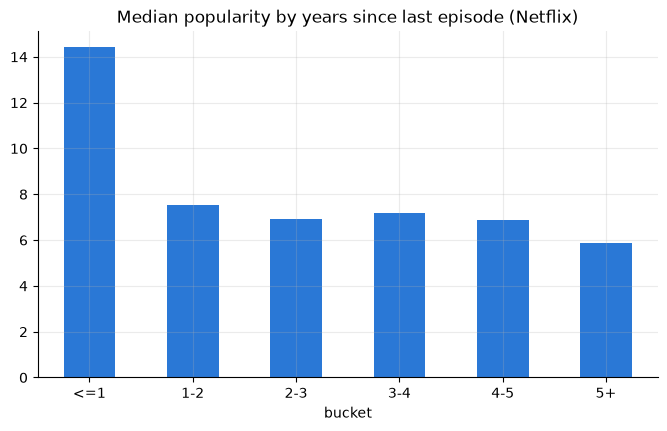

In [7]:
nf2 = nf.dropna(subset=["last_air_date"]).copy()
nf2["yrs_since"] = (pd.Timestamp("2024-01-01") - nf2.last_air_date).dt.days / 365.25
nf2["bucket"] = pd.cut(nf2.yrs_since, [-9, 1, 2, 3, 4, 5, 99], labels=["<=1", "1-2", "2-3", "3-4", "4-5", "5+"])
r = nf2.groupby("bucket", observed=True).popularity.agg(["median", "size"]); print(r.round(2))
r["median"].plot.bar(color=BLUE, rot=0, title="Median popularity by years since last episode (Netflix)"); plt.show()

## 5. Modelling: popularity prediction
**Target:** `log1p(popularity)`. **Pre-launch features only:** genres, language, type, origin country, release year, network, overview length, has homepage.  
**Leaky extras:** vote_count, vote_average, seasons, episodes (only known after launch).  
**Split:** time based on `first_air_date` (train on older shows, test on newer), because random splits let the model see the future.  
Ladder: median baseline, Ridge, gradient boosting, boosting + text. Metrics: MAE and RMSE on log scale, Spearman, top-decile hit rate, bootstrap CI on Spearman.

In [8]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.sparse import hstack, csr_matrix

d = nf.copy()
d = d.sort_values("first_air_date").reset_index(drop=True)
cut = int(len(d) * .75); tr, te = d.iloc[:cut], d.iloc[cut:]
print("train", len(tr), "up to", tr.first_air_date.max().date(), "| test", len(te), "from", te.first_air_date.min().date())

def multi(col, top, fit_cols=None):
    m = d[col].fillna("").str.get_dummies(sep=", ")
    keep = fit_cols if fit_cols is not None else m.sum().sort_values(ascending=False).head(top).index
    return m.reindex(columns=keep, fill_value=0).add_prefix(col + "_")
base = pd.concat([
    multi("genres", 25), multi("origin_country", 15),
    pd.get_dummies(d.original_language.where(d.original_language.isin(["en", "ko", "ja", "es", "fr", "de"]), "other"), prefix="lang"),
    pd.get_dummies(d.type, prefix="type"),
    d[["year"]], d.overview.fillna("").str.len().rename("overview_len"), d.homepage.notna().astype(int).rename("has_homepage")], axis=1).astype(float)
leaky = d[["vote_count", "vote_average", "number_of_seasons", "number_of_episodes"]].astype(float)
tfidf = TfidfVectorizer(max_features=5000, stop_words="english", min_df=3).fit(tr.overview.fillna(""))
svd = TruncatedSVD(30, random_state=0).fit(tfidf.transform(tr.overview.fillna("")))
text = pd.DataFrame(svd.transform(tfidf.transform(d.overview.fillna(""))), columns=[f"svd{i}" for i in range(30)])

yv = d.log_pop.values; ytr, yte = yv[:cut], yv[cut:]
def evaluate(name, pred):
    rho = spearmanr(yte, pred)[0]
    k = max(1, len(yte) // 10)
    hit = len(set(np.argsort(-yte)[:k]) & set(np.argsort(-pred)[:k])) / k
    rng = np.random.default_rng(0); bs = []
    for _ in range(500):
        i = rng.integers(0, len(yte), len(yte)); bs.append(spearmanr(yte[i], pred[i])[0])
    return dict(model=name, MAE=mean_absolute_error(yte, pred), RMSE=mean_squared_error(yte, pred) ** .5,
                spearman=rho, ci_lo=np.nanpercentile(bs, 2.5), ci_hi=np.nanpercentile(bs, 97.5), top_decile_hit=hit)
rows = [evaluate("median baseline", np.full(len(yte), np.median(ytr)))]
def fit_eval(name, F, model):
    model.fit(F.iloc[:cut], ytr); rows.append(evaluate(name, model.predict(F.iloc[cut:])))
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
fit_eval("ridge (pre-launch)", base, make_pipeline(StandardScaler(), Ridge(10)))
hgb = lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=.05, max_depth=4, random_state=0)
fit_eval("boosting (pre-launch)", base, hgb())
fit_eval("boosting + text", pd.concat([base, text], axis=1), hgb())
fit_eval("boosting + post-launch (LEAKY)", pd.concat([base, leaky], axis=1), hgb())
results = pd.DataFrame(rows).set_index("model").round(3); results

train 1319 up to 2022-07-13 | test 440 from 2022-07-13


/var/folders/n5/2bpmbymn69b77rkgn40q7dph0000gn/T/ipykernel_57691/1228930413.py:29: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(yte, pred)[0]
/var/folders/n5/2bpmbymn69b77rkgn40q7dph0000gn/T/ipykernel_57691/1228930413.py:34: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  i = rng.integers(0, len(yte), len(yte)); bs.append(spearmanr(yte[i], pred[i])[0])
/Users/aymanahmed/Documents/Claude/Projects/tmdb_tv_shows/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


,MAE,RMSE,spearman,ci_lo,ci_hi,top_decile_hit
model,,,,,,
median baseline,0.760,0.985,NaN,NaN,NaN,0.205
ridge (pre-launch),0.716,0.962,0.483,0.406,0.553,0.295
boosting (pre-launch),0.646,0.873,0.511,0.442,0.582,0.341
boosting + text,0.652,0.883,0.496,0.417,0.568,0.273
boosting + post-launch (LEAKY),0.666,0.961,0.602,0.525,0.662,0.318


Read it this way: if the pre-launch models barely beat the baseline, that is the honest ceiling with metadata only. The leaky row shows how much a model gets from information it would not have at launch.

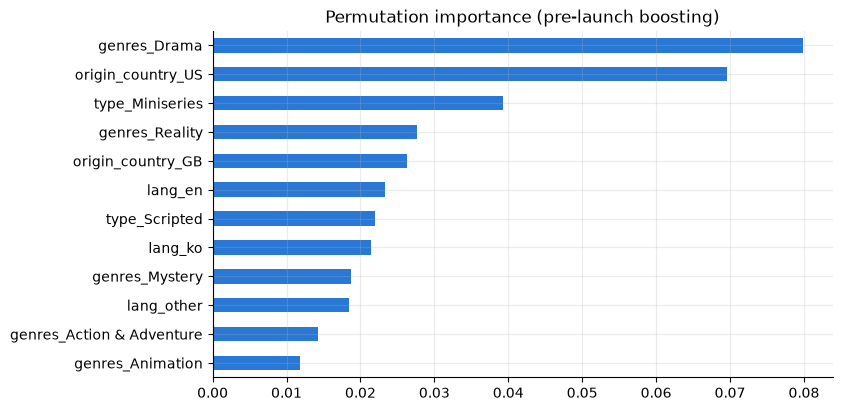

In [9]:
gb = hgb().fit(base.iloc[:cut], ytr)
from sklearn.inspection import permutation_importance
pi = permutation_importance(gb, base.iloc[cut:], yte, n_repeats=10, random_state=0)
imp = pd.Series(pi.importances_mean, index=base.columns).sort_values(ascending=False).head(12)
imp[::-1].plot.barh(color=BLUE, title="Permutation importance (pre-launch boosting)"); plt.show()

### Random split vs time split (leakage in evaluation)

In [10]:
from sklearn.model_selection import KFold, cross_val_predict
comp = []
for label, F in [("pre-launch", base), ("+ post-launch", pd.concat([base, leaky], axis=1))]:
    p = cross_val_predict(hgb(), F, yv, cv=KFold(5, shuffle=True, random_state=0))
    comp.append((label, "random 5-fold", spearmanr(yv, p)[0]))
    m = hgb().fit(F.iloc[:cut], ytr); comp.append((label, "time split", spearmanr(yte, m.predict(F.iloc[cut:]))[0]))
pd.DataFrame(comp, columns=["features", "split", "spearman"]).pivot(index="features", columns="split", values="spearman").round(3)

split,random 5-fold,time split
features,,
+ post-launch,0.844,0.602
pre-launch,0.624,0.511
